# 07. Incidência por estado e anos epidêmicos (P1)

**Pergunta 1:** como a incidência de dengue evoluiu em cada estado do Nordeste entre 2000 e 2025, e quais anos foram
epidêmicos?

| Entrada | Saída |
|---|---|
| `notificacao_dengue_ne`, `populacao_municipio_ano`, `municipio` (tratadas) | tabelas e gráficos de incidência por estado e ano; achados no fim |

**Medidas** (`.claude/specs/03_decisoes.md`): casos **prováveis** (excluídos os classificados como descartados ou chikungunya) por 100 mil
habitantes da população do mesmo ano; confirmados só como comparação. Ano pela data de notificação. Faixas da
incidência anual: **baixa** < 100, **média** 100–299, **alta** ≥ 300 por 100 mil (ano epidêmico = alta).
2025 ainda pode ser revisado pelo Ministério.

**Neste notebook**
1. Dados
2. Nordeste ao longo do tempo
3. Efeito das possíveis duplicatas
4. Incidência por estado
5. Anos epidêmicos
6. Resumo por estado
7. As epidemias acontecem juntas?
8. Achados

In [1]:
import sys
from pathlib import Path
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.append(str(RAIZ / "src"))

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import eda

eda.estilo()

## 1. Dados
Painel município × ano montado em SQL (`eda.painel_municipio_ano`): parte da população, então município sem caso
entra com zero. A soma dos casos do painel tem de ser igual ao total da tabela tratada.

In [2]:
painel = eda.painel_municipio_ano()
total = eda.consulta("""SELECT count(*) AS n FROM notificacao_dengue_ne
                        WHERE caso_provavel AND ano BETWEEN 2000 AND 2025""").n[0]
print(f"{len(painel):,} linhas (município × ano), {painel.cod_mun7.nunique():,} municípios")
print(f"Casos prováveis: painel {painel.provaveis.sum():,} | tabela tratada {total:,}")
assert painel.provaveis.sum() == total

46,627 linhas (município × ano), 1,794 municípios
Casos prováveis: painel 4,178,450 | tabela tratada 4,178,450


In [3]:
def agrega(df, chaves):
    g = df.groupby(chaves, observed=True)[["populacao", "provaveis", "provaveis_sem_dup", "confirmados"]].sum()
    g["inc"] = eda.incidencia(g.provaveis, g.populacao)
    g["inc_sem_dup"] = eda.incidencia(g.provaveis_sem_dup, g.populacao)
    g["inc_confirmados"] = eda.incidencia(g.confirmados, g.populacao)
    return g

ne = agrega(painel, ["ano"])
uf_ano = agrega(painel, ["uf", "ano"])
inc = uf_ano["inc"].unstack("uf")[eda.UFS]          # linhas = ano, colunas = UF
assert uf_ano.provaveis.sum() == ne.provaveis.sum() == total

## 2. Nordeste ao longo do tempo
Barras = incidência de casos prováveis; linha = confirmados, para comparação. As linhas tracejadas marcam os
limites das faixas (100 e 300 por 100 mil).

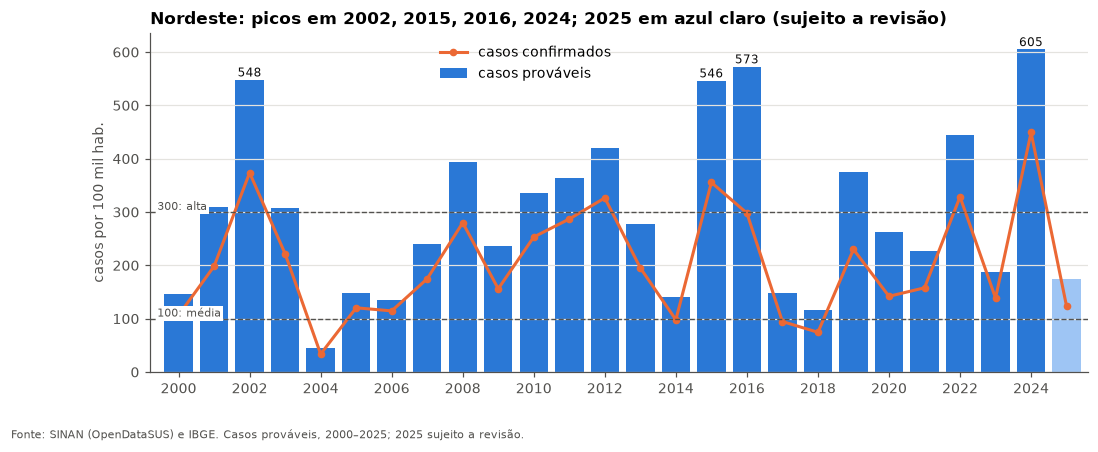

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
cores = [eda.COR["principal"]] * (len(ne) - 1) + ["#9ec5f4"]          # 2025 mais claro: sujeito a revisão
ax.bar(ne.index, ne.inc, color=cores, width=0.8, label="casos prováveis")
ax.plot(ne.index, ne.inc_confirmados, color=eda.COR["comparacao"], marker="o", ms=4, label="casos confirmados")
for limiar, rotulo in [(eda.LIMIAR_MEDIA, "100: média"), (eda.LIMIAR_ALTA, "300: alta")]:
    ax.axhline(limiar, ls="--", lw=0.9, color=eda.COR["limiar"])
    ax.text(1999.4, limiar + 4, rotulo, fontsize=7.5, color=eda.COR["texto2"],
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
for ano in ne.inc.nlargest(4).index:
    ax.text(ano, ne.inc[ano] + 6, f"{ne.inc[ano]:.0f}", ha="center", fontsize=8, color=eda.COR["texto"])
ax.set_xticks(ne.index[::2])
ax.set_xlim(1999.2, 2025.6)
ax.set_ylabel("casos por 100 mil hab.")
ax.set_title(f"Nordeste: picos em {', '.join(map(str, sorted(ne.inc.nlargest(4).index)))}; 2025 em azul claro (sujeito a revisão)")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, 1))
eda.nota(fig)
plt.show()

In [5]:
tab_ne = ne[["populacao", "provaveis", "inc", "confirmados", "inc_confirmados"]].copy()
tab_ne["faixa"] = tab_ne.inc.map(eda.faixa_incidencia)
tab_ne["% confirmados"] = tab_ne.confirmados / tab_ne.provaveis * 100
tab_ne.round(1)

,populacao,provaveis,inc,confirmados,inc_confirmados,faixa,% confirmados
ano,,,,,,,
2000,47782486,70187,146.9,50929,106.6,média,72.6
2001,48331186,149734,309.8,95902,198.4,alta,64.0
2002,48845112,267759,548.2,182581,373.8,alta,68.2
2003,49352225,151541,307.1,109463,221.8,alta,72.2
2004,50427274,22368,44.4,17025,33.8,baixa,76.1
2005,51019091,76039,149.0,61463,120.5,média,80.8
2006,51609027,69757,135.2,59183,114.7,média,84.8
2007,52345293,125608,240.0,91581,175.0,média,72.9
2008,53088496,209255,394.2,148698,280.1,alta,71.1


## 3. Efeito das possíveis duplicatas
As possíveis duplicatas ficam marcadas, não apagadas (decisão 7). Aqui a incidência do Nordeste é calculada com e
sem elas, para ver se a escolha muda alguma conclusão.

In [6]:
dup = pd.DataFrame({
    "com duplicatas": ne.inc, "sem duplicatas": ne.inc_sem_dup,
    "diferença (%)": (ne.inc_sem_dup / ne.inc - 1) * 100,
    "faixa com": ne.inc.map(eda.faixa_incidencia), "faixa sem": ne.inc_sem_dup.map(eda.faixa_incidencia),
})
uf_muda = (uf_ano.inc.map(eda.faixa_incidencia) != uf_ano.inc_sem_dup.map(eda.faixa_incidencia))
print(f"Diferença no Nordeste: de {dup['diferença (%)'].max():.1f}% a {dup['diferença (%)'].min():.1f}%")
print(f"Anos do Nordeste que mudam de faixa: {int((dup['faixa com'] != dup['faixa sem']).sum())}")
print(f"UF-anos que mudam de faixa: {int(uf_muda.sum())} de {len(uf_muda)}",
      list(uf_muda[uf_muda].index) if uf_muda.any() else "")
dup.round(1)

Diferença no Nordeste: de -0.6% a -3.5%
Anos do Nordeste que mudam de faixa: 0
UF-anos que mudam de faixa: 1 de 234 [('PI', 2002)]


,com duplicatas,sem duplicatas,diferença (%),faixa com,faixa sem
ano,,,,,
2000,146.9,144.6,-1.5,média,média
2001,309.8,303.8,-1.9,alta,alta
2002,548.2,532.2,-2.9,alta,alta
2003,307.1,301.4,-1.8,alta,alta
2004,44.4,44.1,-0.6,baixa,baixa
2005,149.0,145.9,-2.1,média,média
2006,135.2,132.5,-2.0,média,média
2007,240.0,236.4,-1.5,média,média
2008,394.2,385.5,-2.2,alta,alta


## 4. Incidência por estado
Mapa de calor estado × ano. A escala linear de cores é a mesma dos mapas estaduais abaixo.

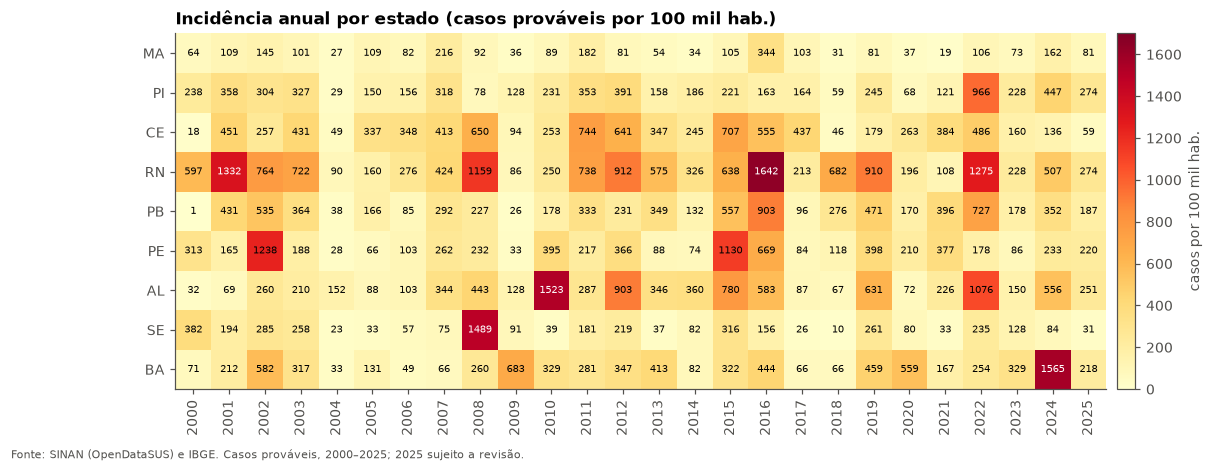

In [7]:
fig, ax = plt.subplots(figsize=(13, 4.2))
escala_incidencia = mpl.colors.Normalize(vmin=0, vmax=np.ceil(inc.to_numpy().max() / 100) * 100)
im = ax.imshow(inc.T, aspect="auto", cmap=eda.SEQUENCIAL, norm=escala_incidencia)
for i, uf in enumerate(inc.columns):
    for j, ano in enumerate(inc.index):
        v = inc.loc[ano, uf]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5,
                color=eda.cor_rotulo(im.cmap(im.norm(v))))
ax.set_xticks(range(len(inc.index)), inc.index, rotation=90)
ax.set_yticks(range(len(inc.columns)), inc.columns)
ax.grid(False)
ax.set_title("Incidência anual por estado (casos prováveis por 100 mil hab.)")
fig.colorbar(im, ax=ax, label="casos por 100 mil hab.", pad=0.01)
eda.nota(fig)
plt.show()

### Distribuição espacial em anos selecionados

Os mapas usam a incidência anual de casos prováveis por 100 mil habitantes. **2002, 2016 e 2024** foram anos de alta incidência no Nordeste. **2025** entra como comparação e está sujeito a revisão. A escala linear de cores é a mesma nos quatro painéis.

Os limites são da [malha estadual simplificada do IBGE](https://servicodados.ibge.gov.br/api/v3/malhas/regioes/2?formato=application%2Fvnd.geo%2Bjson&qualidade=minima&intrarregiao=UF), baixada em 20/11/2026 e armazenada em `src/eda/malha_ne_ibge.geojson`. A mesma malha representa todos os anos.

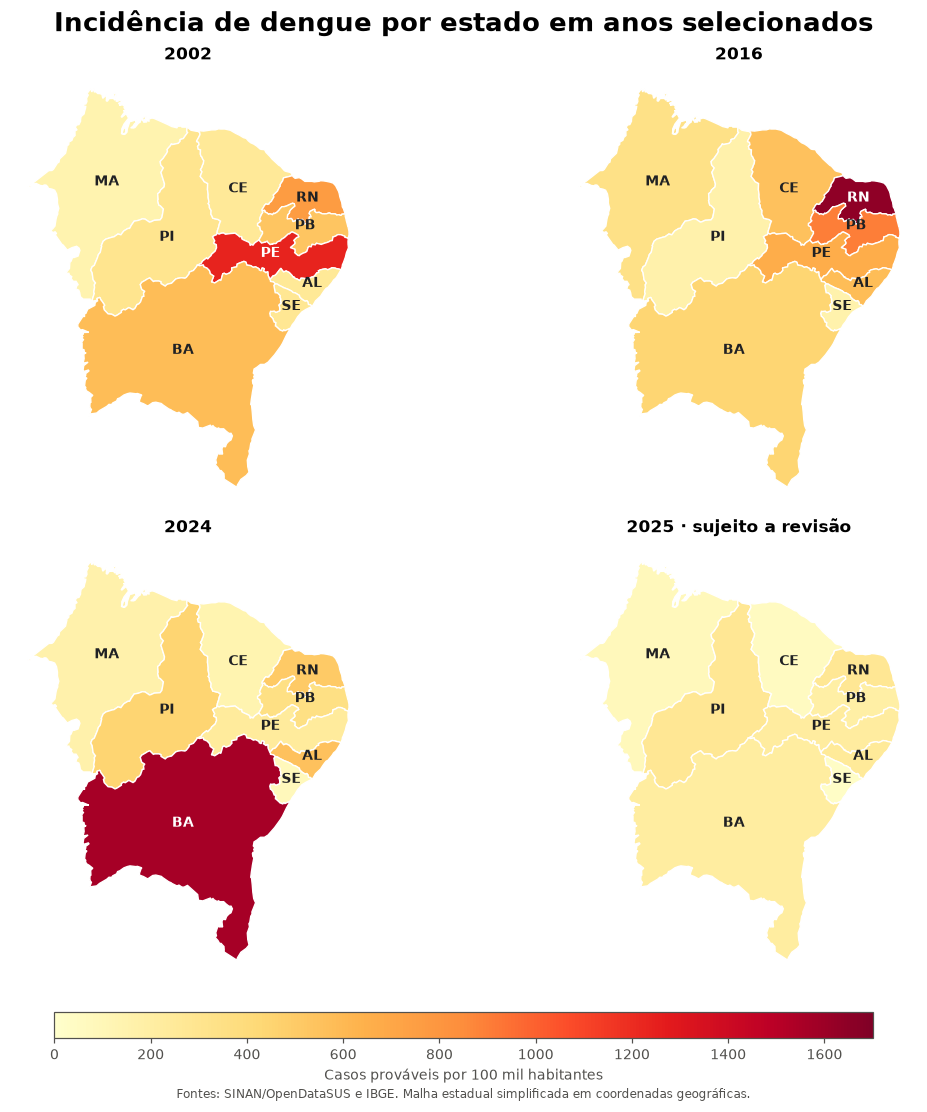

In [8]:
import json

from matplotlib.patches import PathPatch
from matplotlib.path import Path as Caminho

anos_mapa = [2002, 2016, 2024, 2025]
taxas_mapa = inc.loc[anos_mapa, eda.UFS]
malha = json.loads((RAIZ / "src" / "eda" / "malha_ne_ibge.geojson").read_text(encoding="utf-8"))
caminhos = {}
for feicao in malha["features"]:
    uf = eda.UF_SIGLA[int(feicao["properties"]["codarea"])]
    geometria = feicao["geometry"]
    poligonos = geometria["coordinates"]
    if geometria["type"] == "Polygon":
        poligonos = [poligonos]
    caminhos[uf] = Caminho.make_compound_path(
        *(Caminho(anel, closed=True) for poligono in poligonos for anel in poligono)
    )

assert set(caminhos) == set(eda.UFS)
assert np.isfinite(taxas_mapa.to_numpy()).all()
rotulos = {
    "MA": (-45.3, -5.1), "PI": (-42.7, -7.5), "CE": (-39.6, -5.4),
    "RN": (-36.6, -5.8), "PB": (-36.7, -7.0), "PE": (-38.2, -8.2),
    "AL": (-36.4, -9.5), "SE": (-37.3, -10.5), "BA": (-42.0, -12.4),
}

cmap = mpl.colormaps["YlOrRd"]
limite = np.ceil(taxas_mapa.to_numpy().max() / 100) * 100
escala = mpl.colors.Normalize(vmin=0, vmax=limite)
fig, axs = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True, layout="constrained")

for ax, ano in zip(axs.flat, anos_mapa):
    for uf, caminho in caminhos.items():
        cor = cmap(escala(taxas_mapa.at[ano, uf]))
        ax.add_patch(PathPatch(caminho, facecolor=cor, edgecolor="white", linewidth=0.9))
        brilho = 0.2126 * cor[0] + 0.7152 * cor[1] + 0.0722 * cor[2]
        ax.text(*rotulos[uf], uf, ha="center", va="center", fontsize=9, fontweight="bold",
                color="white" if brilho < 0.45 else "#202124")
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.set_axis_off()
    titulo = f"{ano} · sujeito a revisão" if ano == 2025 else str(ano)
    ax.set_title(titulo, loc="center")

fig.suptitle("Incidência de dengue por estado em anos selecionados", fontsize=17, fontweight="bold")
barra = fig.colorbar(mpl.cm.ScalarMappable(norm=escala, cmap=cmap), ax=axs,
                     orientation="horizontal", shrink=0.75, aspect=32, pad=0.03)
barra.set_label("Casos prováveis por 100 mil habitantes")
fig.supxlabel("Fontes: SINAN/OpenDataSUS e IBGE. Malha estadual simplificada em coordenadas geográficas.",
             fontsize=8, color=eda.COR["texto2"])
plt.show()

Cada painel mostra um estado (azul) com o Nordeste como referência (cinza). Escala comum entre os painéis, para
comparar os estados entre si; pontos marcam os anos de incidência alta.

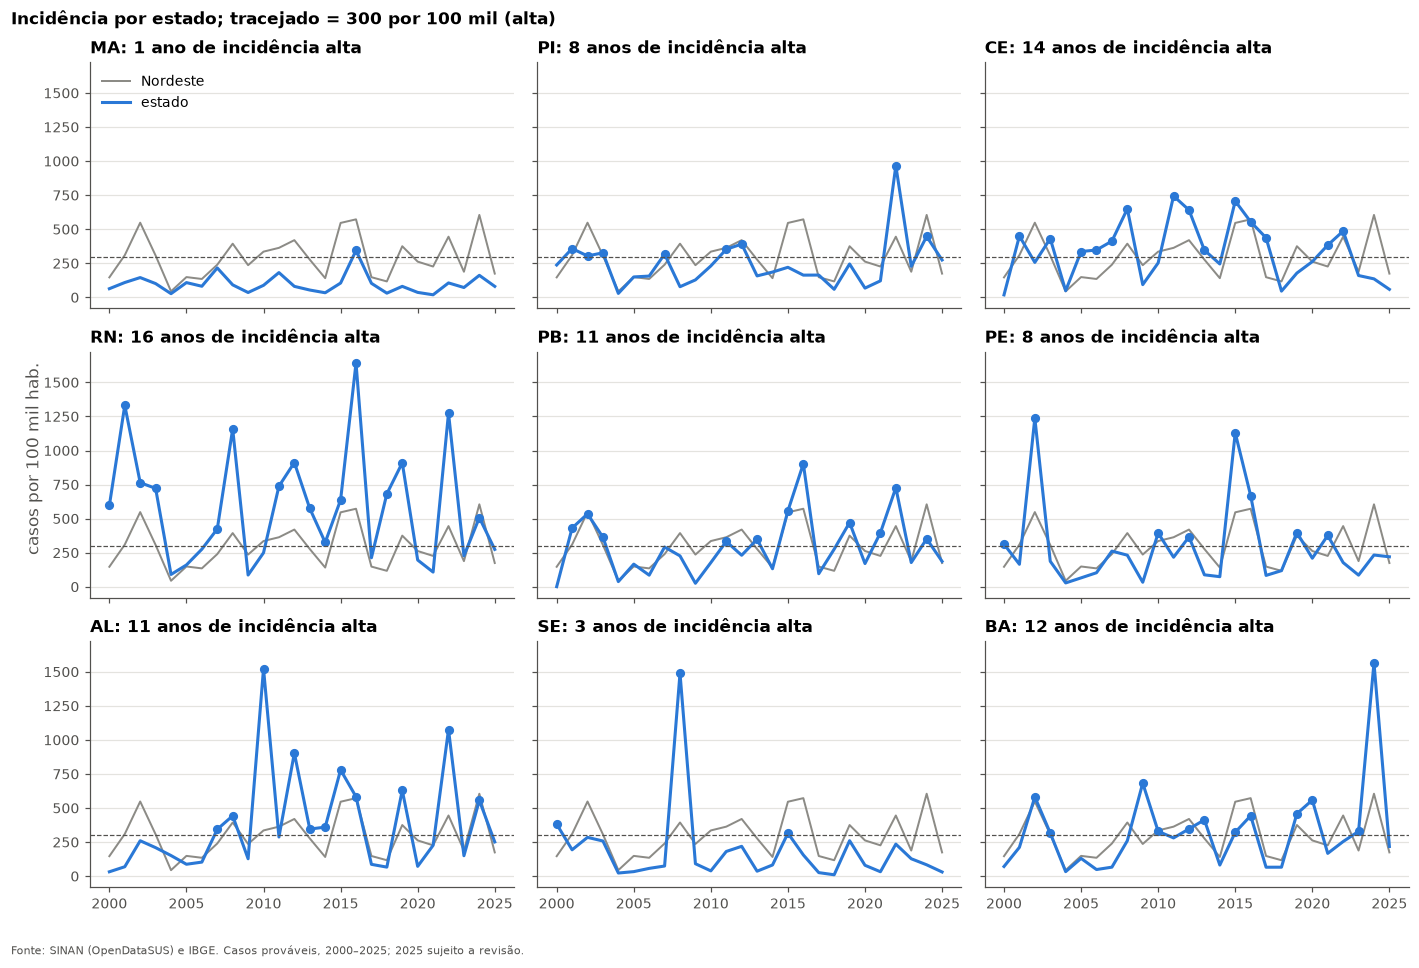

In [9]:
fig, axs = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, uf in zip(axs.ravel(), eda.UFS):
    ax.plot(ne.index, ne.inc, color=eda.COR["referencia"], lw=1.3, label="Nordeste")
    ax.plot(inc.index, inc[uf], color=eda.COR["principal"], label="estado")
    alta = inc[uf] >= eda.LIMIAR_ALTA
    ax.plot(inc.index[alta], inc[uf][alta], "o", ms=5, color=eda.COR["principal"])
    ax.axhline(eda.LIMIAR_ALTA, ls="--", lw=0.8, color=eda.COR["limiar"])
    n = int(alta.sum())
    ax.set_title(f"{uf}: {n} {'ano' if n == 1 else 'anos'} de incidência alta")
axs[0, 0].legend(loc="upper left")
fig.supylabel("casos por 100 mil hab.", color=eda.COR["texto2"])
fig.suptitle("Incidência por estado; tracejado = 300 por 100 mil (alta)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
eda.nota(fig)
plt.show()

## 5. Anos epidêmicos
Faixa de cada estado em cada ano e quantos estados estavam em incidência alta ao mesmo tempo.

In [10]:
faixa = inc.map(eda.faixa_incidencia)
n_alta = (faixa == "alta").sum(axis=1)
anos = pd.DataFrame({
    "estados em alta": n_alta,
    "quais": (faixa == "alta").apply(lambda r: ", ".join(r.index[r]), axis=1),
    "estados em média": (faixa == "média").sum(axis=1),
    "Nordeste": ne.inc.round(0).astype(int).astype(str) + " (" + ne.inc.map(eda.faixa_incidencia) + ")",
})
anos.sort_values(["estados em alta", "estados em média"], ascending=False).head(10)

,estados em alta,quais,estados em média,Nordeste
ano,,,,
2015,7,"CE, RN, PB, PE, AL, SE, BA",2,546 (alta)
2016,7,"MA, CE, RN, PB, PE, AL, BA",2,573 (alta)
2012,6,"PI, CE, RN, PE, AL, BA",2,420 (alta)
2002,5,"PI, RN, PB, PE, BA",4,548 (alta)
2003,5,"PI, CE, RN, PB, BA",4,307 (alta)
2022,5,"PI, CE, RN, PB, AL",4,445 (alta)
2019,5,"RN, PB, PE, AL, BA",3,375 (alta)
2024,5,"PI, RN, PB, AL, BA",3,605 (alta)
2013,5,"CE, RN, PB, AL, BA",1,277 (média)


## 6. Resumo por estado
Incidência média e mediana dos 26 anos, maior valor e ano, coeficiente de variação (CV = desvio ÷ média; quanto maior,
mais a incidência oscila entre anos), anos em cada faixa e a parcela dos prováveis que foi confirmada.

In [11]:
uf_tot = painel.groupby("uf", observed=True)[["provaveis", "confirmados"]].sum()
resumo = pd.DataFrame({
    "média": inc.mean(), "mediana": inc.median(), "máximo": inc.max(), "ano do máximo": inc.idxmax(),
    "CV": inc.std() / inc.mean(),
    "anos alta": (faixa == "alta").sum(), "anos média": (faixa == "média").sum(),
    "% confirmados": uf_tot.confirmados / uf_tot.provaveis * 100,
}).loc[eda.UFS]
resumo.sort_values("média", ascending=False).round(1)

,média,mediana,máximo,ano do máximo,CV,anos alta,anos média,% confirmados
uf,,,,,,,,
RN,580.2,541.2,1642.3,2016,0.7,16,8,39.8
AL,374.2,255.8,1523.1,2010,1.0,11,9,84.1
CE,334.2,341.6,744.0,2011,0.6,14,7,90.7
BA,319.5,270.6,1565.3,2024,1.0,12,7,57.3
PB,296.2,253.7,902.9,2016,0.7,11,10,65.6
PE,287.3,213.3,1237.9,2002,1.0,8,11,72.9
PI,244.8,224.5,966.1,2022,0.7,8,14,86.1
SE,184.9,87.5,1489.3,2008,1.5,3,9,84.8
MA,98.6,85.2,344.2,2016,0.7,1,10,74.6


A parcela confirmada muda muito entre estados e anos, por isso as comparações usam casos prováveis. Exemplo dos
últimos anos:

In [12]:
(uf_ano.confirmados / uf_ano.provaveis * 100).unstack("uf")[eda.UFS].loc[2019:].round(0)

uf,MA,PI,CE,RN,PB,PE,AL,SE,BA
ano,,,,,,,,,
2019,75.0,85.0,96.0,35.0,76.0,59.0,66.0,100.0,54.0
2020,76.0,85.0,89.0,45.0,61.0,53.0,92.0,100.0,41.0
2021,84.0,85.0,95.0,36.0,85.0,45.0,91.0,99.0,54.0
2022,78.0,88.0,93.0,31.0,85.0,53.0,99.0,100.0,60.0
2023,86.0,79.0,98.0,35.0,81.0,44.0,100.0,99.0,70.0
2024,69.0,80.0,97.0,41.0,86.0,65.0,97.0,99.0,73.0
2025,74.0,81.0,92.0,46.0,95.0,74.0,92.0,99.0,57.0


## 7. As epidemias acontecem juntas?
Correlação entre as séries dos estados (logaritmo da incidência, para que um único pico não domine). Valores perto
de 1 indicam estados que sobem e descem nos mesmos anos.

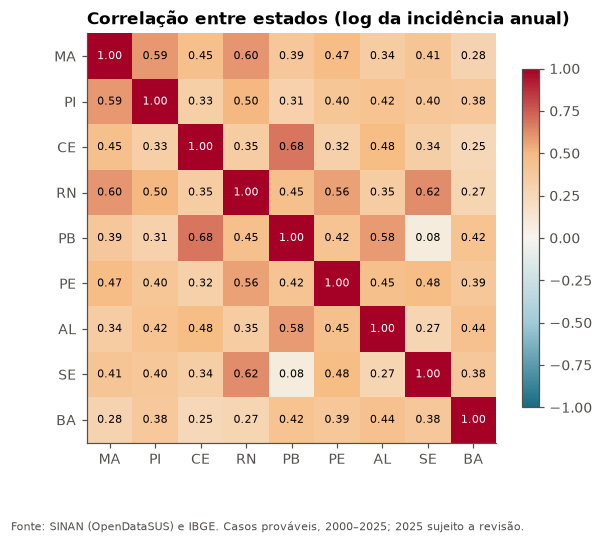

Correlação mediana entre pares: 0.41 (de 0.08 a 0.68)
Pares mais parecidos: CE–PB 0.68, RN–SE 0.62, MA–RN 0.60
Pares menos parecidos: PB–SE 0.08, CE–BA 0.25, RN–BA 0.27


In [13]:
corr = np.log1p(inc).corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap=eda.DIVERGENTE, vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color=eda.cor_rotulo(im.cmap(im.norm(corr.iloc[i, j]))))
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
ax.set_title("Correlação entre estados (log da incidência anual)")
fig.colorbar(im, ax=ax, shrink=0.8)
eda.nota(fig)
plt.show()

par = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print(f"Correlação mediana entre pares: {par.median():.2f} (de {par.min():.2f} a {par.max():.2f})")
print("Pares mais parecidos:", ", ".join(f"{a}–{b} {v:.2f}" for (a, b), v in par.nlargest(3).items()))
print("Pares menos parecidos:", ", ".join(f"{a}–{b} {v:.2f}" for (a, b), v in par.nsmallest(3).items()))

## 8. Achados
- **Nordeste:** incidência alta (≥ 300 por 100 mil) em 12 dos 26 anos, média em 13 e baixa só em 2004 (44). Os
  maiores valores foram 2024 (605), 2016 (573), 2002 (548) e 2015 (546). 2025 (175, faixa média) ainda pode ser revisado.
- **Epidemias regionais:** 2015 e 2016 tiveram 7 dos 9 estados em incidência alta; 2012 teve 6.
- **Estados:** RN tem a maior incidência média (580 por 100 mil por ano) e 16 anos em alta; MA tem a menor (99) e um
  único ano em alta (2016). SE é o mais irregular (CV 1,5): mediana de 88, mas pico de 1.489 em 2008.
- **Picos estaduais:** RN 2016 (1.642), BA 2024 (1.565), AL 2010 (1.523), SE 2008 (1.489) e PE 2002 (1.238).
- **Sincronia moderada:** correlação mediana de 0,41 entre os estados (CE–PB 0,68; PB–SE 0,08). As epidemias não
  acontecem ao mesmo tempo em todo o Nordeste.
- **Duplicatas:** retirar as possíveis duplicatas reduz a incidência do Nordeste em 0,6% a 3,5% por ano; nenhum ano
  muda de faixa e só 1 de 234 estado-anos muda (PI 2002).
- **Confirmação:** a parcela dos prováveis confirmada vai de 40% (RN) a 91% (CE) no período; comparar estados por
  confirmados distorceria o resultado.
- **Cuidados:** 2014, 2015 e 2022–2025 vêm sem descartados no arquivo (`05_analise`), então nesses anos provável =
  notificado e a incidência pode estar um pouco acima da dos outros anos. Valores muito baixos no início (PB 2000 = 1;
  CE 2000 = 18) parecem falha de notificação, não ausência de dengue.